# Efeitos das bets no Brasil — análise rápida

Exploração inicial de quatro dimensões: **endividamento**, **inadimplência**, **consumo** e **saúde mental**,
mais as medidas de **exposição** (Pix, Bolsa Família) que servirão para identificação.

Os dados são gerados pelos scripts em `src/` (sempre rodando da raiz do projeto):

```bash
uv run python -m src.pipeline            # APIs leves (minutos)
uv run python -m src.pipeline --pesado   # + SCR, Bolsa Família, DATASUS (horas, dezenas de GB)
```

Cada seção abaixo pula sozinha se o arquivo correspondente ainda não foi gerado.

> **Convenção:** toda escolha que não é ditada pelos dados (deflator, janela, definição de CID,
> interpolação, exclusões) aparece num bloco **Decisão** explicando o quê e por quê.

In [1]:
import sys
from pathlib import Path

# Raiz do projeto = primeira pasta acima (ou igual) ao cwd que tenha pyproject.toml.
# Funciona rodando da raiz ou de notebooks/ (o Jupyter/VS Code usa a pasta do notebook como cwd).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from src.config import CHOQUES, COPAS, HOJE, PANDEMIA, PROCESSED

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def carregar(nome: str) -> pl.DataFrame | None:
    p = PROCESSED / f"{nome}.parquet"
    if not p.exists():
        print(f"⚠ {p.relative_to(ROOT)} não existe — rode o script correspondente em src/")
        return None
    return pl.read_parquet(p)


def em_pandemia(col: str = "data") -> pl.Expr:
    ini, fim = (pl.lit(d).str.to_date() for d in PANDEMIA)
    return pl.col(col).is_between(ini, fim)


def marcar_choques(ax, desde="2018-01-01"):
    if PANDEMIA[1] >= desde:
        ini, fim = pl.Series(PANDEMIA).str.to_date()
        ax.axvspan(max(ini, pl.Series([desde]).str.to_date()[0]), fim, color="gray", alpha=0.15, lw=0)
        ax.text(fim, 0.02, "pandemia ", ha="right", va="bottom", fontsize=7, color="dimgray",
                transform=ax.get_xaxis_transform())
    for rotulo, (ini, fim) in COPAS.items():
        if fim >= desde:
            ini, fim = pl.Series([ini, fim]).str.to_date()
            ax.axvspan(ini, fim, color="goldenrod", alpha=0.25, lw=0)
            ax.text(ini, 0.02, rotulo + " ", rotation=90, ha="right", va="bottom", fontsize=7,
                    color="darkgoldenrod", transform=ax.get_xaxis_transform())
    for d, rotulo in CHOQUES.items():
        if d >= desde:
            x = pl.Series([d]).str.to_date()[0]
            ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
            ax.text(x, 1.0, " " + rotulo, rotation=90, va="top", ha="right", fontsize=7,
                    color="crimson", transform=ax.get_xaxis_transform())

## Linha do tempo regulatória

| Data | Marco |
|---|---|
| dez/2018 | Lei 13.756 cria as apostas de quota fixa (sem regulamentação) |
| 2020–2023 | Expansão sem regulação: patrocínios, publicidade massiva |
| dez/2023 | Lei 14.790 regulamenta o setor |
| out/2024 | Bloqueio de sites não autorizados; vedação de uso de recursos do Bolsa Família |
| jan/2025 | Início do mercado regulado (operadores autorizados pela SPA/MF) |
| 25/set/2026 | **MP 1.394** proíbe as bets (depósitos vetados; saques até 05/10; sites fora do ar em 06/10) |

**Decisão — período:** começamos em **jan/2018**, um ano antes da Lei 13.756, para ter pré-período.
As linhas vermelhas nos gráficos são esses marcos (definidos em `src/config.py::CHOQUES`).
As faixas douradas são as Copas do Mundo (`src/config.py::COPAS`): não são choques, mas são picos de apostas que podem confundir janelas curtas (a Copa de 2026 terminou dois meses antes da MP).
A MP 1.394 é o choque mais limpo (abrupto, nacional, data exata), mas é recente: em nov/2026 só há 1–2 meses
pós-choque na maioria das séries, e a MP pode caducar em mar/2027.

## ⚠ Pandemia de Covid-19 (2020–2021)

A fase de **expansão** das bets (2020–2023) coincide com a pandemia, que afetou quase todos os outcomes por canais
próprios, mais fortes que qualquer efeito plausível das apostas:

| Outcome | Como a pandemia contamina |
|---|---|
| Endividamento | Renda das famílias caiu e depois foi sustentada pelo Auxílio Emergencial (abr/2020–out/2021); o denominador (renda) oscila. Selic a 2% barateou o crédito |
| Inadimplência | Repactuações e carências de 2020 seguraram a inadimplência artificialmente, seguidas de alta em 2021–22 |
| Consumo | Colapso em abr/2020, recuperação desigual (bens antes de serviços); a PMS só normaliza em 2022 |
| Pix | Lançado em nov/2020, em plena pandemia: o crescimento até ~2022 é **adoção do meio de pagamento**, não apostas |
| Saúde | Cirurgias e internações eletivas suspensas, CAPS com atendimento reduzido, e choque próprio de saúde mental (isolamento, luto) |

**Decisão — período atípico:** tratamos **mar/2020 a dez/2021** como pandemia (faixa cinza nos gráficos;
`src/config.py::PANDEMIA`). O início é o das primeiras restrições. O fim é dez/2021 porque o Auxílio Emergencial
acabou em out/2021 e as séries de consumo e do SUS voltam à tendência até o fim de 2021. A emergência sanitária
(ESPIN) só terminou em abr/2022, e `PANDEMIA_LONGA` (até abr/2022) fica disponível como teste de robustez.

**Decisões de identificação decorrentes:**
1. **A fase 2018–2023 é só descritiva.** Não tentamos estimar o efeito causal da legalização/expansão com séries
   temporais nacionais, porque é impossível separá-la da pandemia.
2. **Os choques usados para inferência são pós-pandemia:** out/2024 (vedação PBF/bloqueios), jan/2025 (regulação)
   e set/2026 (MP 1.394). Os pré-períodos dessas análises começam em **jan/2022 ou depois**.
3. **Medidas de exposição** (Pix per capita, PBF share) são medidas em **2024**, depois que a adoção do Pix
   estabilizou. Usar Pix de 2020–21 mediria adoção, não apostas.
4. **Se um modelo usar a série longa** (2018→), a pandemia entra com dummies mensais próprias (ou os meses
   são excluídos) e reportamos os dois.
5. **Saúde:** além de taxas por população, olhamos a **participação no total de internações**. Isso neutraliza
   a queda geral de atendimentos na pandemia, que derrubaria qualquer taxa per capita.

## Deflator

**Decisão — preços:** valores nominais em R$ (Pix, Bolsa Família, carteira de crédito) são convertidos para
**R$ constantes do último mês disponível pelo IPCA** (SGS 433). Escolhemos o IPCA por ser o índice oficial de
inflação ao consumidor; para crédito poderia-se argumentar por outro deflator, mas a diferença é pequena e o IPCA
facilita comparar com renda. Séries já em % ou em número-índice real (endividamento/renda, inadimplência,
volume da PMC/PMS) **não** são deflacionadas.

In [2]:
sgs_end = carregar("endividamento_sgs")
ipca = (
    sgs_end.select("data", "ipca_mensal").drop_nulls().sort("data")
    .with_columns(((1 + pl.col("ipca_mensal") / 100).cum_prod()).alias("indice"))
    .with_columns((pl.col("indice").last() / pl.col("indice")).alias("fator_real"))
    .select("data", "fator_real")
)
print("base do deflator:", ipca["data"].max())


def deflacionar(df: pl.DataFrame, col_data: str, cols: list[str]) -> pl.DataFrame:
    # Meses após o último IPCA publicado ficam com fator 1 (assumimos inflação ~0 nesse intervalo curto).
    return (
        df.join(ipca, left_on=col_data, right_on="data", how="left")
        .with_columns(pl.col("fator_real").fill_null(1.0))
        .with_columns([(pl.col(c) * pl.col("fator_real")).alias(c + "_real") for c in cols])
        .drop("fator_real")
    )

base do deflator: 2026-09-01


**Decisão — meses sem IPCA:** o IPCA sai ~10 dias após o fim do mês, então os 1–2 meses mais recentes
ficam com fator 1 (sem correção). Num período tão curto isso introduz erro de no máximo ~0,5%.

---
# 1. Endividamento

Séries do BCB/SGS (Brasil, mensal):
- **29037** endividamento das famílias / renda acumulada em 12 meses (%); **29038** idem, sem habitacional
- **29034 / 29035** comprometimento de renda com serviço da dívida (total / sem habitacional)

**Decisão:** priorizamos as versões **sem financiamento habitacional**. O crédito imobiliário é de longo prazo e
não deve responder a gastos com apostas; o canal plausível é crédito pessoal, cartão e cheque especial.

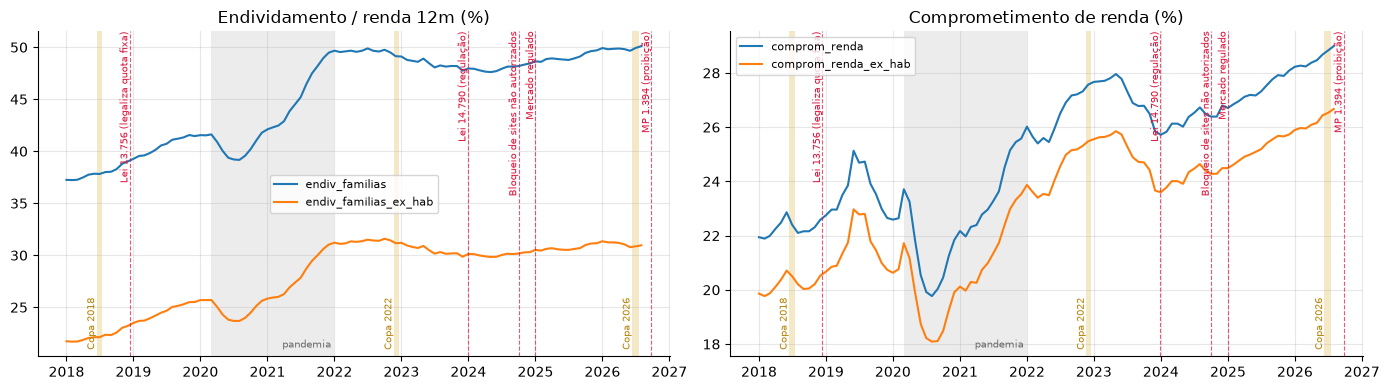

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, cols, titulo in [
    (axes[0], ["endiv_familias", "endiv_familias_ex_hab"], "Endividamento / renda 12m (%)"),
    (axes[1], ["comprom_renda", "comprom_renda_ex_hab"], "Comprometimento de renda (%)"),
]:
    for c in cols:
        d = sgs_end.select("data", c).drop_nulls()
        ax.plot(d["data"], d[c], label=c)
    marcar_choques(ax); ax.set_title(titulo); ax.legend(fontsize=8)
plt.tight_layout()

Text(0.5, 1.0, 'Concessões de crédito a pessoas físicas')

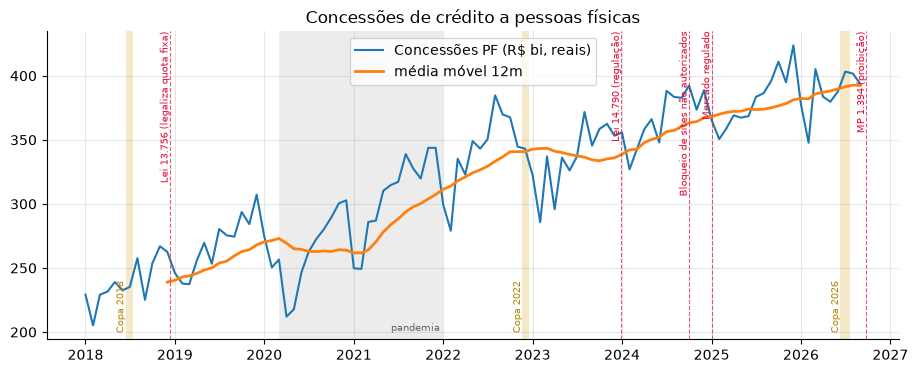

In [4]:
cred = deflacionar(sgs_end, "data", ["saldo_credito_pf", "concessoes_pf"])
fig, ax = plt.subplots()
ax.plot(cred["data"], cred["concessoes_pf_real"] / 1e3, label="Concessões PF (R$ bi, reais)")
ax.plot(cred["data"], cred["concessoes_pf_real"].rolling_mean(12) / 1e3, label="média móvel 12m", lw=2)
marcar_choques(ax); ax.legend(); ax.set_title("Concessões de crédito a pessoas físicas")

**Decisão — média móvel de 12 meses:** concessões têm sazonalidade forte (13º, fim de ano); a média de 12 meses
remove isso sem impor um modelo de ajuste sazonal. Para inferência usaremos dummies de mês.

---
# 2. Inadimplência

## 2.1 Agregado nacional (SGS)
**21082** total; **21084** pessoas físicas; **21112** PF com recursos livres. Definição do BCB:
saldo com atraso **acima de 90 dias** / carteira total.

Text(0.5, 1.0, 'Inadimplência (%)')

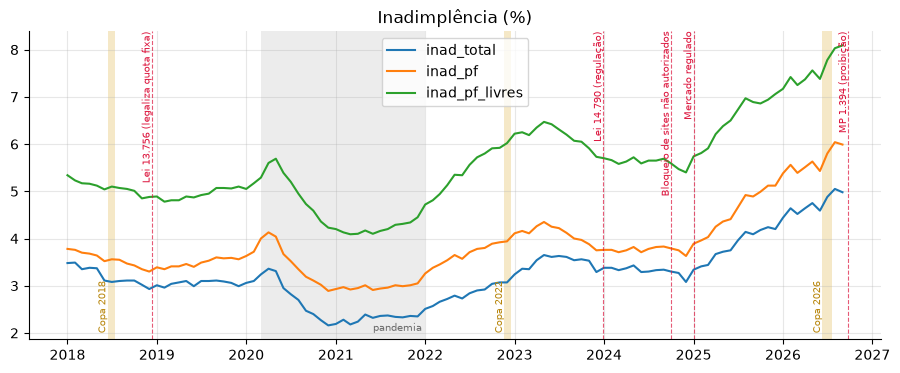

In [5]:
inad = carregar("inadimplencia_sgs")
fig, ax = plt.subplots()
for c in ["inad_total", "inad_pf", "inad_pf_livres"]:
    ax.plot(inad["data"], inad[c], label=c)
marcar_choques(ax); ax.legend(); ax.set_title("Inadimplência (%)")

## 2.2 SCR.data por UF, ocupação e faixa de renda

**Decisão — definição de inadimplência no SCR:** usamos `carteira_inadimplida_arrastada / carteira_ativa`.
"Arrastada" significa que, se uma parcela de um contrato passa de 90 dias de atraso, o contrato inteiro conta
como inadimplido (critério do BCB). O nível **não é idêntico** ao da série 21084, mas o objetivo aqui é variação
entre UFs e grupos, não o nível.

**Decisão — `numero_de_operacoes`:** valores "<= 15" (suprimidos por sigilo) viram nulo e não entram na soma;
por isso usamos saldos (R$), não contagens.

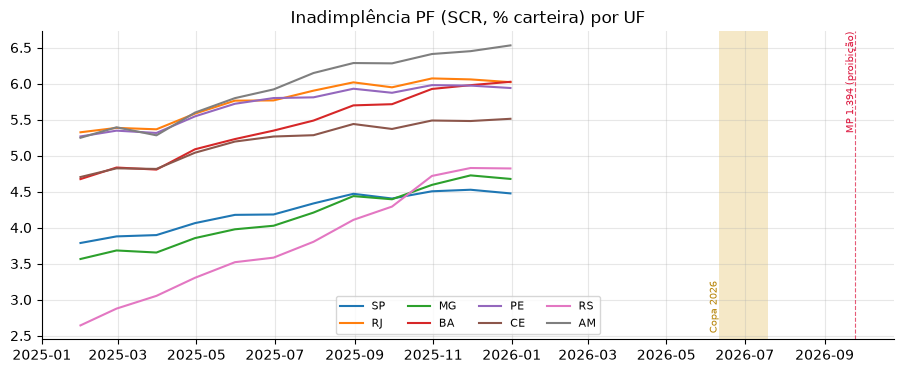

In [6]:
scr = carregar("scr_pf_uf_mes")
if scr is not None:
    s = scr.sort("data_base")
    fig, ax = plt.subplots()
    for uf in ["SP", "RJ", "MG", "BA", "PE", "CE", "RS", "AM"]:
        d = s.filter(pl.col("uf") == uf)
        ax.plot(d["data_base"], d["inad_pct"], label=uf)
    marcar_choques(ax, str(s["data_base"].min())); ax.legend(ncol=4, fontsize=8)
    ax.set_title("Inadimplência PF (SCR, % carteira) por UF")

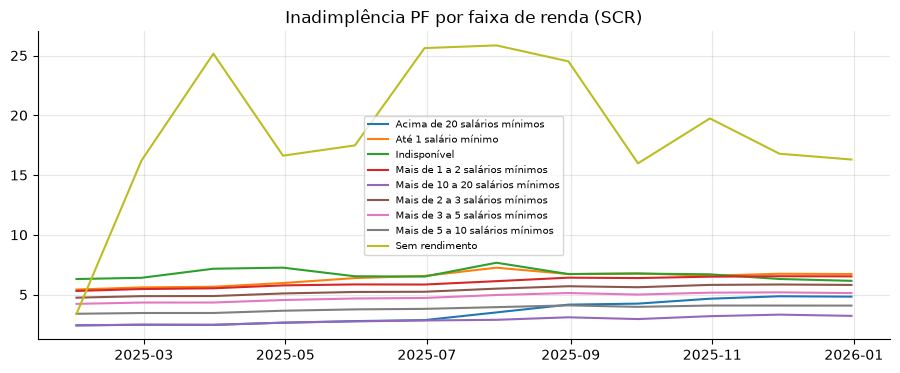

In [7]:
scr_full = carregar("scr_pf_uf")
if scr_full is not None:
    por_renda = (
        scr_full.group_by("data_base", "porte")
        .agg(pl.col("carteira_inadimplida_arrastada", "carteira_ativa").sum())
        .with_columns((pl.col("carteira_inadimplida_arrastada") / pl.col("carteira_ativa") * 100).alias("inad_pct"))
        .sort("data_base")
    )
    fig, ax = plt.subplots()
    for porte in sorted(por_renda["porte"].unique().drop_nulls()):
        d = por_renda.filter(pl.col("porte") == porte)
        ax.plot(d["data_base"], d["inad_pct"], label=porte.replace("PF - ", ""))
    ax.legend(fontsize=7); ax.set_title("Inadimplência PF por faixa de renda (SCR)")

**Heterogeneidade por renda:** a hipótese é que o efeito das bets se concentre nas faixas de renda mais baixas.
O SCR separa PF por faixa de renda (`porte`) e ocupação, o que permite comparar grupos dentro da mesma UF e mês.

---
# 3. Consumo — PMC e PMS (IBGE)

**Decisão — ajuste sazonal e volume:** usamos o **índice de volume com ajuste sazonal** (2022=100).
Volume, e não receita nominal, porque queremos quantidade consumida (já descontada a inflação do setor).
O ajuste sazonal do próprio IBGE (X-13) evita que efeitos de calendário se confundam com choques regulatórios.

**Decisão — PMS:** a tabela nova 8688 só tem dados para o Brasil, então para UF usamos a **5906**
(mesma base 2022=100 e os mesmos valores nacionais).

Text(0.5, 1.0, 'Volume (com ajuste sazonal, 2022=100) — Brasil')

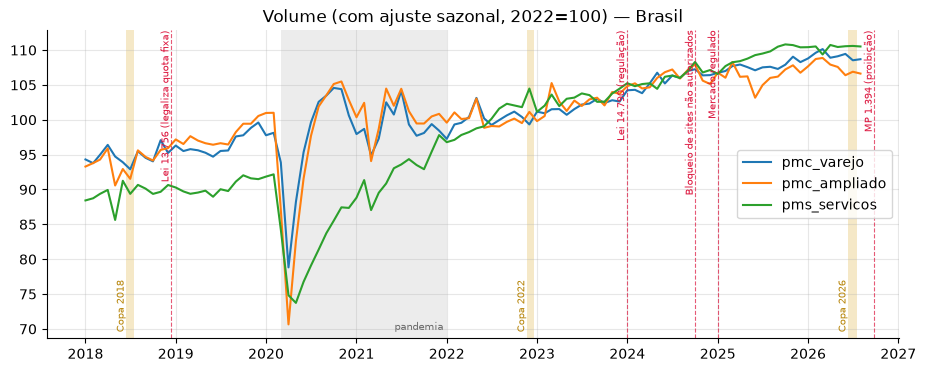

In [8]:
cons = carregar("consumo_pmc_pms")
br = cons.filter(
    (pl.col("cod_uf") == "1")
    & pl.col("variavel").str.contains("ajuste sazonal")
    & pl.col("indice").str.contains("volume")
    & (pl.col("data") >= pl.date(2018, 1, 1))
).sort("data")
fig, ax = plt.subplots()
for p in ["pmc_varejo", "pmc_ampliado", "pms_servicos"]:
    d = br.filter(pl.col("pesquisa") == p)
    ax.plot(d["data"], d["valor"], label=p)
marcar_choques(ax); ax.legend(); ax.set_title("Volume (com ajuste sazonal, 2022=100) — Brasil")

---
# 4. Exposição: Pix por município

O BCB publica o Pix **total** por município (não o Pix destinado a bets, que é sigiloso). Ele serve para:
1. ver a quebra agregada após a MP 1.394 (o BCB reportou queda de ~10% no nº de transações);
2. construir intensidade de exposição pré-choque, cruzando a variação municipal com o Bolsa Família.

**Decisão — mês corrente:** o último mês da API é **parcial** (os dados de nov/2026 cobrem só os dias já
decorridos) e é **descartado**. Os 3 meses mais recentes são sempre baixados de novo pelo script, porque o BCB revisa.

**Decisão — métrica:** usamos **valor pago por pessoas físicas** (`VL_PagadorPF`), porque apostas são
pagamentos PF→PJ. Normalizamos por **população** e deflacionamos pelo IPCA.

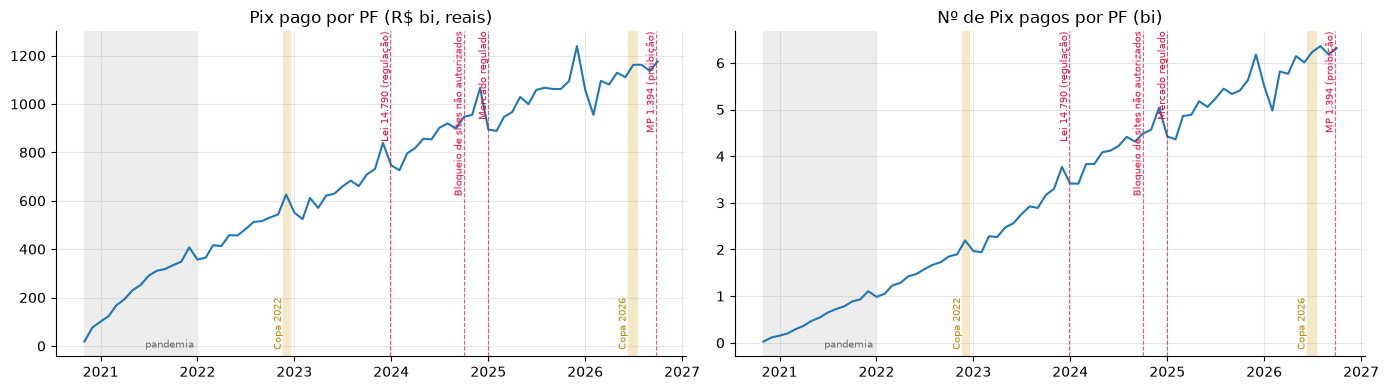

In [9]:
pix = carregar("pix_municipio")
mes_corrente = HOJE.year * 100 + HOJE.month
pix = pix.filter(pl.col("AnoMes") < mes_corrente).with_columns(
    pl.col("AnoMes").cast(pl.String).str.to_date("%Y%m").alias("data")
)
pix = deflacionar(pix, "data", ["VL_PagadorPF", "VL_PagadorPJ"])
nac = pix.group_by("data").agg(pl.col("VL_PagadorPF_real", "QT_PagadorPF").sum()).sort("data")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(nac["data"], nac["VL_PagadorPF_real"] / 1e9); axes[0].set_title("Pix pago por PF (R$ bi, reais)")
axes[1].plot(nac["data"], nac["QT_PagadorPF"] / 1e9); axes[1].set_title("Nº de Pix pagos por PF (bi)")
for ax in axes: marcar_choques(ax, "2020-11-01")
plt.tight_layout()

## 4.1 População municipal

**Decisão — interpolação da população:** a tabela 6579 (estimativas do IBGE) **não tem 2022 nem 2023**
(2022 foi ano de Censo e não houve estimativa em 2023). Preenchemos esses anos por **interpolação linear**
entre 2021 e 2024, para cada município. Alternativas: usar o Censo 2022 (tabela 4709), que tem uma quebra
metodológica em relação às estimativas, ou repetir o último valor. A interpolação linear é a escolha mais
neutra para crescimento populacional, que é suave ao longo de 3 anos.
Anos posteriores à última estimativa repetem o último valor disponível.

**Decisão — Pix sem município:** o BCB publica uma linha "NÃO INFORMADO" por mês (Pix sem município
identificado). Ela não tem população e fica **fora** das medidas per capita, mas entra nos totais nacionais.

In [10]:
pop = carregar("populacao_municipio")
anos = pl.DataFrame({"ano": list(range(pop["ano"].min(), HOJE.year + 1))}, schema={"ano": pl.Int32})
pop = (
    pop.select("cod_ibge").unique().join(anos, how="cross")
    .join(pop, on=["cod_ibge", "ano"], how="left").sort("cod_ibge", "ano")
    .with_columns(pl.col("populacao").cast(pl.Float64).interpolate().forward_fill().over("cod_ibge"))
)
pix_pc = (
    pix.with_columns(pl.col("data").dt.year().cast(pl.Int32).alias("ano"))
    .join(pop, left_on=["Municipio_Ibge", "ano"], right_on=["cod_ibge", "ano"], how="left")
    .with_columns((pl.col("VL_PagadorPF_real") / pl.col("populacao")).alias("pix_pf_pc"))
)
sem_pop = pix_pc.filter(pl.col("populacao").is_null())
print("linhas sem população:", sem_pop.height, sem_pop["Municipio"].unique().to_list())

linhas sem população: 72 ['N/D']


## 4.2 Variação em torno da MP 1.394

Primeira olhada: variação do Pix PF per capita de **ago/2026** (antes da MP) para **out/2026** (primeiro mês
cheio sem bets), por UF.

**Decisão — janela:** comparamos ago contra out, e não set contra out, porque setembro é um mês "contaminado":
teve 24 dias com bets e 6 sem, além de uma corrida de saques. Comparar meses diferentes do ano mistura
sazonalidade, então o ideal é um diff-in-diff contra a mesma variação ago→out de 2025; fazemos isso abaixo.

uf,var_202608_202610,var_202508_202510,diff_in_diff_pp
str,f64,f64,f64
"""DISTRITO FEDERAL""",0.060709,0.364057,-0.303348
"""MINAS GERAIS""",-0.593457,-0.328103,-0.265354
"""MATO GROSSO DO SUL""",-0.665805,-0.451059,-0.214745
"""ALAGOAS""",1.826475,1.736371,0.090105
"""MATO GROSSO""",0.112561,-0.057619,0.17018
…,…,…,…
"""CEARÁ""",2.584949,-0.713286,3.298235
"""RORAIMA""",6.907241,3.182119,3.725122
"""RIO GRANDE DO SUL""",2.887172,-1.161995,4.049167


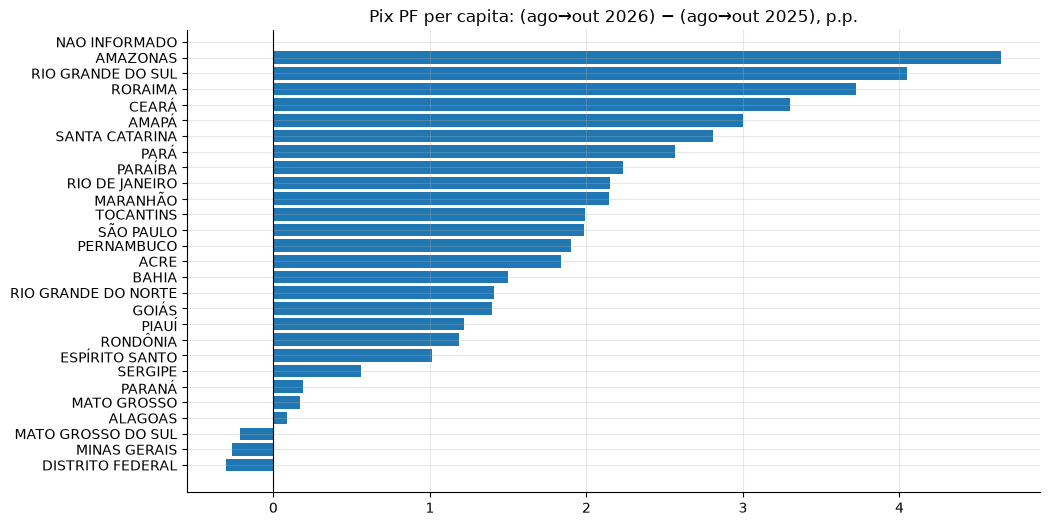

In [11]:
def var_uf(ini, fim):
    a = (pix_pc.filter(pl.col("AnoMes").is_in([ini, fim]))
         .group_by("AnoMes", pl.col("Estado").alias("uf"))
         .agg(pl.col("VL_PagadorPF_real").sum(), pl.col("populacao").sum())
         .with_columns((pl.col("VL_PagadorPF_real") / pl.col("populacao")).alias("pc"))
         .pivot(on="AnoMes", index="uf", values="pc"))
    return a.with_columns(((pl.col(str(fim)) / pl.col(str(ini)) - 1) * 100).alias(f"var_{ini}_{fim}")).select("uf", f"var_{ini}_{fim}")

if (pix_pc["AnoMes"] == 202610).any():
    dd = var_uf(202608, 202610).join(var_uf(202508, 202510), on="uf")
    dd = dd.with_columns((pl.col("var_202608_202610") - pl.col("var_202508_202510")).alias("diff_in_diff_pp")).sort("diff_in_diff_pp")
    display(dd)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(dd["uf"], dd["diff_in_diff_pp"]); ax.axvline(0, color="k", lw=0.8)
    ax.set_title("Pix PF per capita: (ago→out 2026) − (ago→out 2025), p.p.")
else:
    print("out/2026 ainda não disponível")

---
# 4b. Exposição: Google Trends

Separado em **`notebooks/google_trends.ipynb`**. Resumo: as buscas por apostas têm pico em 2023 e despencam em
out/2026 depois da MP 1.394 (~40 → ~13). A queda é maior nas UFs mais expostas. O nível de 2024 por UF
(`trends_2024`) é a medida de exposição a cruzar com SCR, PMC/PMS e DATASUS.


---
# 5. Bolsa Família

Pagamentos por município. Usado como **intensidade de exposição** (segundo o Estudo Especial do BCB de set/2024, beneficiários do PBF
enviaram cerca de R$ 3 bi a bets via Pix em ago/2024), e como grupo de interesse por causa da
vedação de out/2024.

**Decisão — chave de município:** o arquivo da CGU traz código **SIAFI**, não IBGE. Casamos por
**nome normalizado (sem acento, maiúsculo) + UF**. ~30 municípios têm grafia antiga no SIAFI
(ex.: EMBU → Embu das Artes, PARATI → Paraty, ACU → Assu) e são corrigidos por uma tabela manual
(`ALIASES` em `src/exposicao/bolsa_familia.py`), conferida contra o cadastro do IBGE. Em ago/2024, 100% dos
municípios casaram. Se aparecer algum sem código em outros meses, ele é listado pelo script e **excluído** aqui.

**Decisão — medida de exposição:** `beneficiários / população` em **ago/2024**, o mês do estudo do BCB e anterior
à vedação de out/2024, o que dá uma medida pré-tratamento.

In [12]:
pbf = carregar("bolsa_familia_municipio")
if pbf is not None:
    print("sem código IBGE (excluídos):", pbf["cod_ibge"].null_count())
    expo = (
        pbf.filter((pl.col("anomes") == "202408") & pl.col("cod_ibge").is_not_null())
        .join(pop.filter(pl.col("ano") == 2024), on="cod_ibge")
        .with_columns((pl.col("beneficiarios") / pl.col("populacao")).alias("pbf_share"))
        .select("cod_ibge", "uf", "pbf_share", "valor_pbf")
    )
    display(expo.describe())

sem código IBGE (excluídos): 0


statistic,cod_ibge,uf,pbf_share,valor_pbf
str,f64,str,f64,f64
"""count""",5570.0,"""5570""",5570.0,5570.0
"""null_count""",0.0,"""0""",0.0,0.0
"""mean""",3.2536e6,null,0.124557,2.4307e6
"""std""",984910.339431,null,0.076202,1.0088e7
"""min""",1.100015e6,"""AC""",0.001731,5160.0
"""25%""",2.512101e6,null,0.059795,324640.0
"""50%""",3.146305e6,null,0.108742,858471.0
"""75%""",4.119202e6,null,0.186629,2.186254e6
"""max""",5.300108e6,"""TO""",0.501099,4.35436042e8


## 5.1 Exposição × queda do Pix pós-MP (município)

Se as bets drenavam renda de municípios mais dependentes do PBF, a proibição deveria reduzir mais o Pix PF
nesses municípios. Variação ago→out/2026 menos ago→out/2025, por quintil de `pbf_share`.

**Decisão — quintis:** usamos quintis em vez de regressão linear nesta etapa exploratória, para ver se a relação
é monotônica sem impor forma funcional. A diferença de variações é **winsorizada** nos percentis 1 e 99, porque municípios
muito pequenos geram variações extremas (um único pagamento grande muda tudo) que dominariam as médias.

In [13]:
if pbf is not None and (pix_pc["AnoMes"] == 202610).any():
    def var_mun(ini, fim):
        w = pix_pc.filter(pl.col("AnoMes").is_in([ini, fim])).pivot(on="AnoMes", index="Municipio_Ibge", values="pix_pf_pc")
        return w.select("Municipio_Ibge", (pl.col(str(fim)) / pl.col(str(ini)) - 1).alias(f"v{fim}"))
    m = var_mun(202608, 202610).join(var_mun(202508, 202510), on="Municipio_Ibge")
    m = m.with_columns((pl.col("v202610") - pl.col("v202510")).alias("dd"))
    lo, hi = m["dd"].quantile(0.01), m["dd"].quantile(0.99)
    m = m.with_columns(pl.col("dd").clip(lo, hi))
    q = (m.join(expo, left_on="Municipio_Ibge", right_on="cod_ibge")
         .with_columns(("Q" + (pl.col("pbf_share").rank("ordinal") * 5 / pl.len()).ceil().cast(pl.Int32).cast(pl.String)).alias("quintil_pbf"))
         .group_by("quintil_pbf").agg(pl.col("dd").mean() * 100, pl.len()).sort("quintil_pbf"))
    display(q)

quintil_pbf,dd,len
str,f64,u32
"""Q1""",1.156767,1114
"""Q2""",0.776159,1114
"""Q3""",0.546578,1114
"""Q4""",1.843814,1114
"""Q5""",2.776292,1114


---
# 6. Saúde mental (DATASUS)

Três fontes, agregadas por **município de residência** e mês:
- **SIH-RD** internações: `intern_f63`, `intern_mental` (F00–F99), `intern_subst` (F10–F19), `intern_autolesao` (X60–X84)
- **SIA-PS** RAAS/CAPS (atenção psicossocial): `raas_f63`, `pacientes_f63`, ...
- **SIM** óbitos: `obitos_suicidio` (CAUSABAS X60–X84)

**Decisões — CID:**
- Usamos **F63 inteiro** (transtornos de hábitos e impulsos) e não só F63.0 (jogo patológico), porque a
  codificação no SUS frequentemente para em 3 caracteres. Isso inclui cleptomania e piromania, raras.
- No SIH, F63 e autolesão contam em **diagnóstico principal ou secundário**. Jogo raramente é o motivo principal
  da internação, mas aparece como comorbidade. Os demais grupos de F contam só no principal.
- No SIA-PS contamos só o **CID principal** (`CIDPRI`).

**Decisão — taxas:** taxas por 100 mil habitantes, com a população interpolada da seção 4.1.

**Decisão — código de município:** o DATASUS usa **6 dígitos** (IBGE sem dígito verificador). Casamos pelos
6 primeiros dígitos do código IBGE.

⚠ F63 é muito raro. Em UFs pequenas, as contagens mensais são quase sempre zero, então a análise municipal deve
agregar no tempo (trimestre/ano) ou usar modelos de contagem (Poisson/NegBin), não taxas brutas.

arquivos SIH baixados (UF de internação): ['AC']


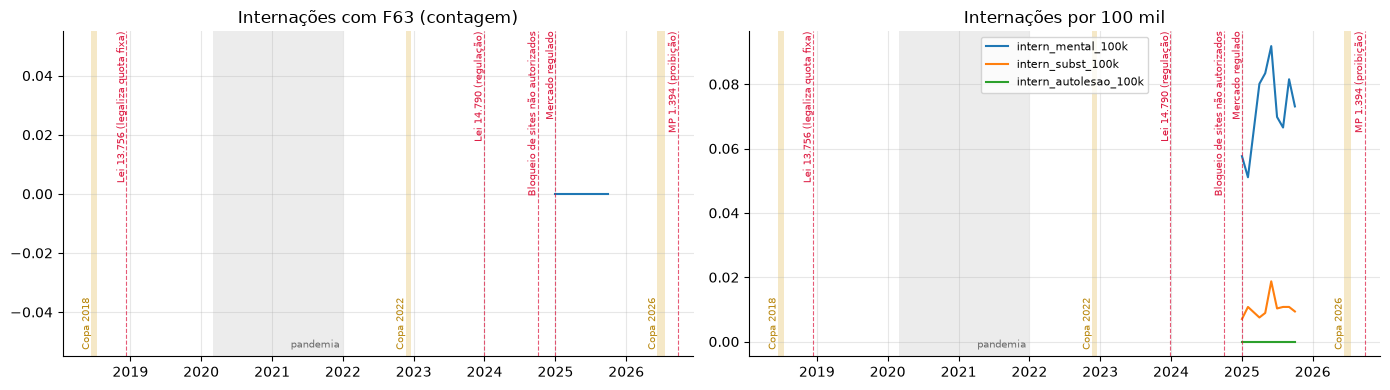

In [14]:
pop6 = pop.with_columns(pl.col("cod_ibge").cast(pl.String).str.slice(0, 6).alias("cod_mun6"))

def taxa_nacional(df, cols, col_ano="ano", col_mes="mes"):
    t = df.group_by(col_ano, col_mes).agg(pl.col(cols).sum()).with_columns(
        pl.date(pl.col(col_ano), pl.col(col_mes), 1).alias("data"))
    p = pop6.group_by("ano").agg(pl.col("populacao").sum())
    t = t.join(p, left_on=col_ano, right_on="ano", how="left")
    return t.with_columns([(pl.col(c) / pl.col("populacao") * 1e5).alias(c + "_100k") for c in cols]).sort("data")

sih = carregar("sih_mental_municipio")
if sih is not None:
    print("arquivos SIH baixados (UF de internação):", sorted({p.stem[2:4] for p in (ROOT / "data/interim/sih").glob("*.parquet")}))
    t = taxa_nacional(sih, ["intern_f63", "intern_mental", "intern_subst", "intern_autolesao"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(t["data"], t["intern_f63"]); axes[0].set_title("Internações com F63 (contagem)")
    for c in ["intern_mental_100k", "intern_subst_100k", "intern_autolesao_100k"]:
        axes[1].plot(t["data"], t[c], label=c)
    axes[1].legend(fontsize=8); axes[1].set_title("Internações por 100 mil")
    for ax in axes: marcar_choques(ax)
    plt.tight_layout()

⚠ **Cobertura:** a taxa nacional só faz sentido depois de rodar o SIH para **todas** as UFs; com poucas UFs
baixadas, o denominador (população do Brasil) subestima a taxa. A célula acima mostra de quais UFs os arquivos foram baixados. Atenção: como agregamos por município de
**residência**, aparecem também municípios de outras UFs (pacientes internados fora do seu estado). Para
taxas por UF, só considere UFs cujos arquivos e os das UFs vizinhas foram baixados.

**Participação no total (efeito da pandemia):** a célula abaixo mostra cada grupo como **% de todas as
internações**. Em 2020 o total despencou (eletivas suspensas), e a participação evita ler essa queda geral como
mudança em saúde mental.

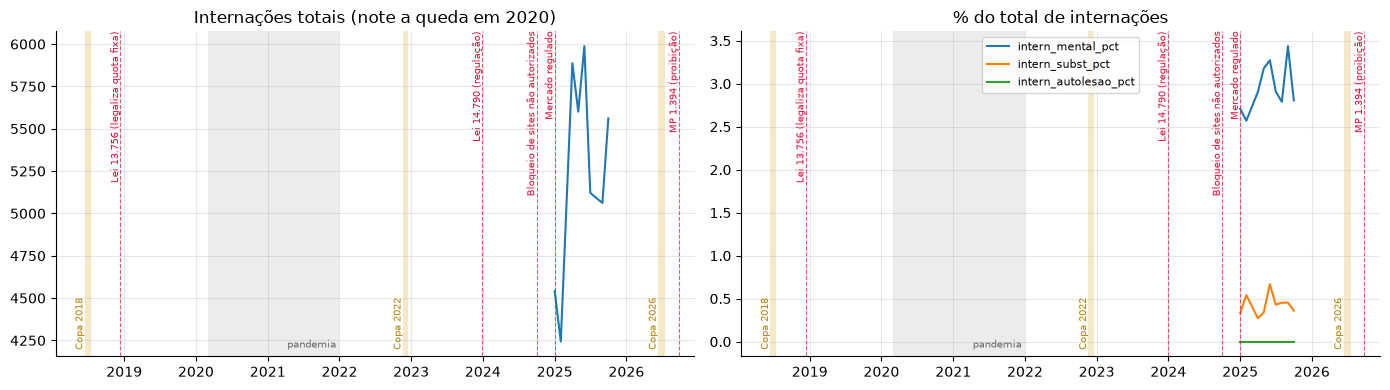

In [15]:
if sih is not None:
    grupos = ["intern_mental", "intern_subst", "intern_autolesao"]
    t = (sih.group_by("ano", "mes").agg(pl.col("intern_total", *grupos).sum())
         .with_columns(pl.date("ano", "mes", 1).alias("data")).sort("data")
         .with_columns([(pl.col(c) / pl.col("intern_total") * 100).alias(c + "_pct") for c in grupos]))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(t["data"], t["intern_total"]); axes[0].set_title("Internações totais (note a queda em 2020)")
    for c in ["intern_mental_pct", "intern_subst_pct", "intern_autolesao_pct"]:
        axes[1].plot(t["data"], t[c], label=c)
    axes[1].legend(fontsize=8); axes[1].set_title("% do total de internações")
    for ax in axes: marcar_choques(ax)
    plt.tight_layout()

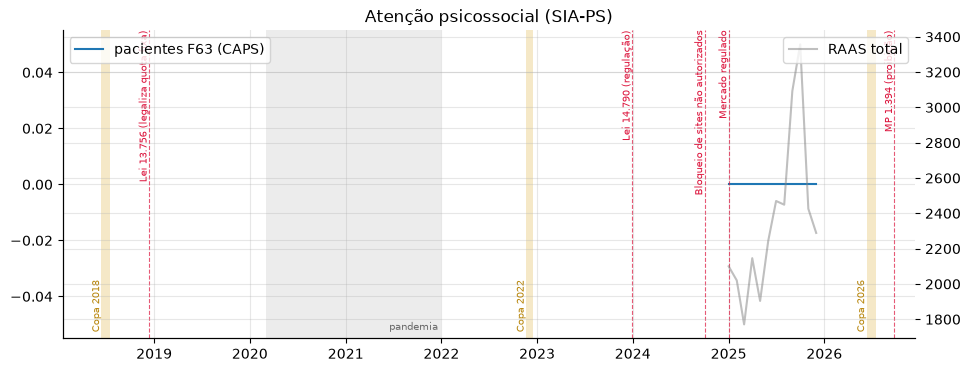

In [16]:
sia = carregar("sia_caps_municipio")
if sia is not None:
    s = (sia.group_by("cmp").agg(pl.col("raas_total", "raas_f63", "pacientes_f63", "raas_subst").sum())
         .with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data")).sort("data"))
    fig, ax = plt.subplots()
    ax.plot(s["data"], s["pacientes_f63"], label="pacientes F63 (CAPS)")
    ax2 = ax.twinx(); ax2.plot(s["data"], s["raas_total"], color="gray", alpha=0.5, label="RAAS total")
    ax.legend(loc="upper left"); ax2.legend(loc="upper right"); marcar_choques(ax)
    ax.set_title("Atenção psicossocial (SIA-PS)")

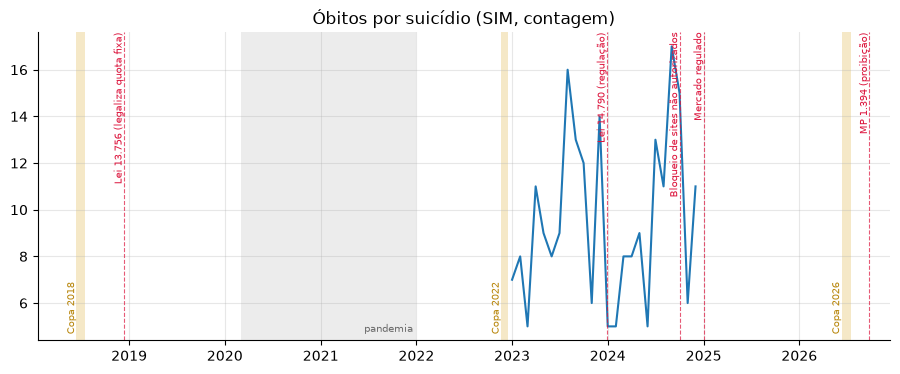

In [17]:
sim = carregar("sim_suicidio_municipio")
if sim is not None:
    t = taxa_nacional(sim.drop_nulls(["ano", "mes"]), ["obitos_suicidio"])
    fig, ax = plt.subplots()
    ax.plot(t["data"], t["obitos_suicidio"]); marcar_choques(ax)
    ax.set_title("Óbitos por suicídio (SIM, contagem)")

---
# Próximos passos

1. Rodar o pipeline pesado completo (SCR 2018→, SIH/SIA/SIM todas UFs, PBF mensal).
2. Montar painel município × mês com exposição pré-tratamento (PBF share, Pix PF per capita em 2024).
3. Event study em torno de out/2024 (vedação PBF), jan/2025 (regulação) e set/2026 (MP 1.394),
   com efeitos fixos de município e mês. Erros padrão clusterizados por município.
4. Heterogeneidade: SCR por faixa de renda e ocupação; saúde mental por faixa etária e sexo.
5. Testes de placebo: mesma janela em anos anteriores; outcomes que não deveriam responder.
6. Robustez à pandemia: repetir tudo com `PANDEMIA_LONGA` (até abr/2022), e com pré-período começando
   em 2023 em vez de 2022.